In [2]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [3]:
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.2
N = 100000

In [4]:
# create an array of 50 standard normal distributed values
rng = np.random.default_rng(7)
Z = rng.normal(0, 1, N)

In [5]:
# create function of terminal playoffs S_t
St = S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)



In [6]:
x = np.maximum(St - K, 0)

value_estimate = np.exp(-r*T) * 1/N * np.sum(x)
value_estimate

np.float64(10.406663781668192)

In [7]:
c = 0.95

In [8]:
sigma_estimate = np.std(x, ddof=1)
SE_estimate = np.exp(-r * T) * sigma_estimate / np.sqrt(N)
s = - norm.ppf((1 - c) / 2)

In [9]:
CI = [value_estimate - s * SE_estimate, value_estimate + s * SE_estimate]
print(CI)

[np.float64(10.315813007388371), np.float64(10.497514555948012)]


# extend estimate to put options

In [10]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

In [11]:
def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [12]:
bs_price, _ = black_scholes_price(S0, K, T, r, sigma)
print(bs_price)

10.450583572185565


In [21]:
n_values = np.logspace(2, 5, 50, dtype=int)
n_array = np.array(n_values)
reference = np.exp(-r*T) * np.std(x, ddof=1) / np.sqrt(n_array)
rng = np.random.default_rng(4)
M = 100

errors = []
estimates = []

for n in n_values:

    Z = rng.normal(0, 1, size = (M,n))
    St = S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)
    x = np.maximum(St - K, 0)
    value_estimate = np.exp(-r*T) * np.sum(x, axis = 1) / n

    mean_price = np.mean(value_estimate)
    estimates.append(mean_price)

    RMSE_estimate = np.sqrt(np.mean((value_estimate - bs_price)**2))
    errors.append(RMSE_estimate)


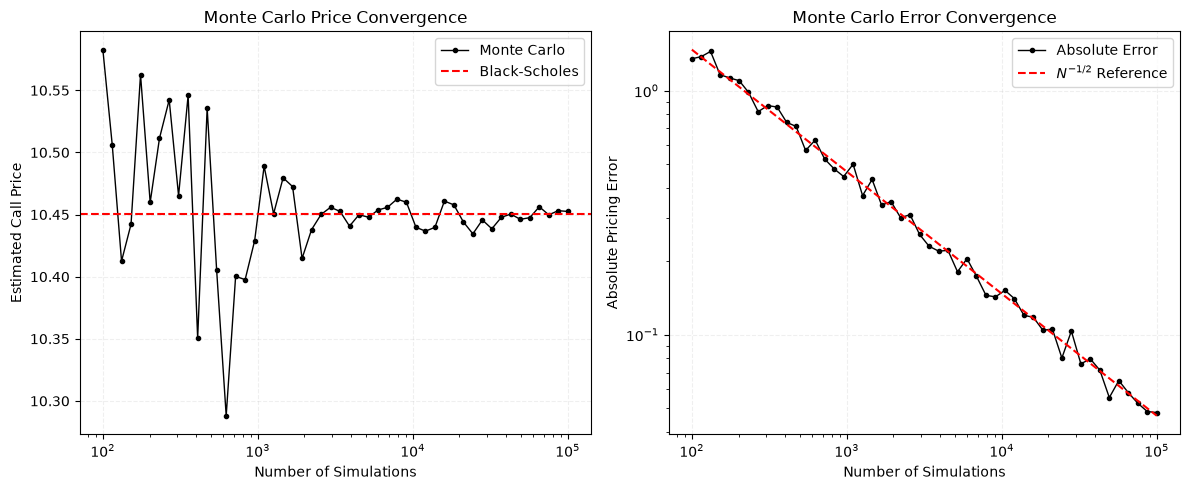

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Monte Carlo price convergence
axs[0].plot(n_values, estimates, color="black",
            linewidth = 1, marker = ".", label = "Monte Carlo")

axs[0].axhline(bs_price, color="red",
               linestyle = "--", label = "Black-Scholes")

axs[0].set_xscale("log")
axs[0].set_xlabel("Number of Simulations")
axs[0].set_ylabel("Estimated Call Price")
axs[0].set_title("Monte Carlo Price Convergence")
axs[0].legend()
axs[0].grid(alpha = 0.2, linestyle = "--")

# Absolute pricing error
axs[1].plot(n_values, errors, color = "black",
            linewidth = 1, marker = ".", label = "Absolute Error")

axs[1].plot(n_array, reference, color = "red",
            linestyle = "--", linewidth = 1.5,
            label = r"$N^{-1/2}$ Reference")

axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set_xlabel("Number of Simulations")
axs[1].set_ylabel("Absolute Pricing Error")
axs[1].set_title("Monte Carlo Error Convergence")
axs[1].grid(True, which = "major", alpha = 0.2, linestyle = "--")
axs[1].legend()

plt.tight_layout()
plt.show()

### Antithetic Variations in Monte Carlo

In [20]:
n_values = np.unique(2 * (np.logspace(2, 5, 50, dtype=int) // 2))
rng = np.random.default_rng(4)
M = 100

errors_antithetic = []
estimates_antithetic = []

for n in n_values:

    Z = rng.normal(0, 1, size = (M, n//2))

    Stx = S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)
    Sty = S0 * np.exp((r - 0.5 * sigma ** 2) * T - sigma * np.sqrt(T) * Z)

    x = np.maximum(Stx - K, 0)
    y = np.maximum(Sty - K, 0)

    z = (x + y) / 2

    value_estimate = np.exp(-r*T) * np.sum(z, axis = 1) / (n//2)

    mean_price = np.mean(value_estimate)
    estimates_antithetic.append(mean_price)

    RMSE_estimate = np.sqrt(np.mean((value_estimate - bs_price)**2))
    errors_antithetic.append(RMSE_estimate)

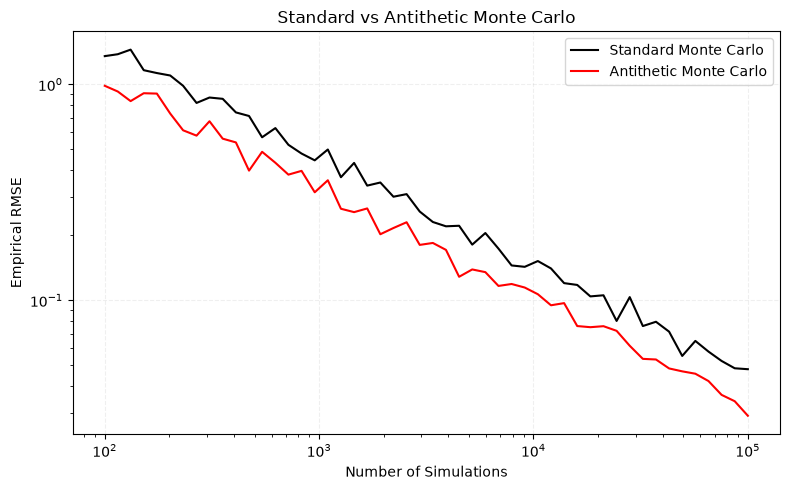

In [22]:
plt.figure(figsize = (8, 5))

plt.plot(n_values, errors,
         color = "black", linewidth = 1.5,
         label = "Standard Monte Carlo")

plt.plot(n_values, errors_antithetic,
         color = "red", linewidth = 1.5,
         label = "Antithetic Monte Carlo")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of Simulations")
plt.ylabel("Empirical RMSE")
plt.title("Standard vs Antithetic Monte Carlo")

plt.grid(True, which = "major", alpha = 0.2, linestyle = "--")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
idx = np.argmin(np.abs(np.array(n_values) - 10000))
factor = (errors[idx] / errors_antithetic[idx])**2

print("MSE reduction factor:", factor)

MSE reduction factor: 2.029256304780449


### Control Variates in Monte Carlo

In [24]:
rng = np.random.default_rng(4)

# Estimate beta using an independent pilot sample
Z_pilot = rng.normal(0, 1, 50000)

St_pilot = S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z_pilot)

X_pilot = np.exp(-r * T) * np.maximum(St_pilot - K, 0)
Y_pilot = np.exp(-r * T) * St_pilot

beta = np.cov(X_pilot, Y_pilot)[0, 1] / np.var(Y_pilot, ddof=1)

# Control variate simulation
errors_control = []
estimates_control = []

for n in n_values:

    Z = rng.normal(0, 1, (M, n))

    St = S0 * np.exp((r - 0.5 * sigma ** 2) * T + sigma * np.sqrt(T) * Z)

    X = np.exp(-r * T) * np.maximum(St - K, 0)
    Y = np.exp(-r * T) * St

    value_estimate = np.mean(X, axis = 1) + beta * (S0 - np.mean(Y, axis = 1))

    mean_price = np.mean(value_estimate)
    RMSE_estimate = np.sqrt(np.mean((value_estimate - bs_price) ** 2))

    estimates_control.append(mean_price)
    errors_control.append(RMSE_estimate)

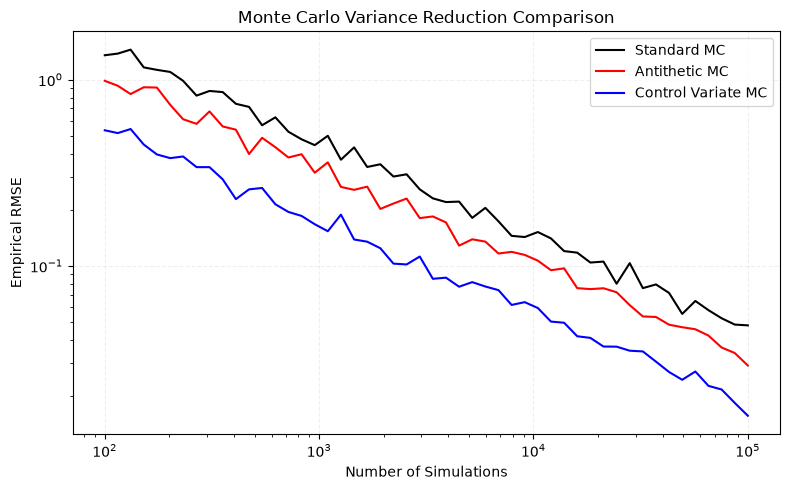

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(n_values, errors,
         color="black", linewidth=1.5,
         label="Standard MC")

plt.plot(n_values, errors_antithetic,
         color="red", linewidth=1.5,
         label="Antithetic MC")

plt.plot(n_values, errors_control,
         color="blue", linewidth=1.5,
         label="Control Variate MC")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of Simulations")
plt.ylabel("Empirical RMSE")
plt.title("Monte Carlo Variance Reduction Comparison")

plt.grid(True, which="major", alpha=0.2, linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
idx = np.argmin(np.abs(np.array(n_values) - 10000))

factor = (errors[idx] / errors_control[idx])**2

print("Estimated beta:", beta)
print("MSE reduction factor:", factor)

Estimated beta: 0.6726406739597852
MSE reduction factor: 6.5394365958813045
